# Семинар 3. Продвинутые техники работы с данными для построения модели линейной регрессии. Подбор гиперпараметров

Подгрузим данные с соревнования https://www.kaggle.com/c/house-prices-advanced-regression-techniques/overview

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

In [2]:
import warnings

warnings.filterwarnings('ignore')

In [3]:
train_path = 'train.csv'

In [4]:
train_data = pd.read_csv(train_path)

In [5]:
len(train_data)

1460

In [6]:
train_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
train_data.select_dtypes('object')

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
1,RL,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
3,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,...,Detchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Abnorml
4,RL,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
1456,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,Attchd,Unf,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal
1457,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,Norm,...,Attchd,RFn,TA,TA,Y,NaN,GdPrv,Shed,WD,Normal
1458,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal


In [8]:
train_data.select_dtypes(np.number)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,...,0,61,0,0,0,0,0,2,2008,208500
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,...,298,0,0,0,0,0,0,5,2007,181500
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,0,42,0,0,0,0,0,9,2008,223500
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,...,0,35,272,0,0,0,0,2,2006,140000
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,192,84,0,0,0,0,0,12,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,62.0,7917,6,5,1999,2000,0.0,0,...,0,40,0,0,0,0,0,8,2007,175000
1456,1457,20,85.0,13175,6,6,1978,1988,119.0,790,...,349,0,0,0,0,0,0,2,2010,210000
1457,1458,70,66.0,9042,7,9,1941,2006,0.0,275,...,0,60,0,0,0,0,2500,5,2010,266500
1458,1459,20,68.0,9717,5,6,1950,1996,0.0,49,...,366,0,112,0,0,0,0,4,2010,142125


## Обработка данных

Выкинем индекс

In [9]:
train_data = train_data.drop(columns=['Id'])

In [10]:
cat_over_columns = ['Street', 'Alley', 'LandContour','Utilities','Condition2',
                    'RoofMatl','BsmtCond','Heating','Electrical','Functional','GarageQual','GarageCond','PavedDrive']
train_data = train_data.drop(columns=cat_over_columns)

In [11]:
too_much_na_columns = ['PoolQC', 'Fence', 'MiscFeature']
train_data = train_data.drop(columns=too_much_na_columns)

Заполним пропуски средним

In [12]:
numeric_feats = train_data.select_dtypes(np.number).columns
mean = train_data[numeric_feats].mean()
train_data[numeric_feats] = train_data[numeric_feats].fillna(mean)

In [13]:
numeric_feats = list(numeric_feats)
numeric_feats.remove('SalePrice')

In [14]:
cat_feats = train_data.select_dtypes(object).columns
mode = train_data.mode().iloc[0]
train_data[cat_feats] = train_data[cat_feats].fillna(mode)

In [15]:
train_data

,MSSubClass,MSZoning,LotFrontage,LotArea,LotShape,LotConfig,LandSlope,Neighborhood,Condition1,BldgType,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Reg,Inside,Gtl,CollgCr,Norm,1Fam,...,0,0,0,0,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Reg,FR2,Gtl,Veenker,Feedr,1Fam,...,0,0,0,0,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,IR1,Inside,Gtl,CollgCr,Norm,1Fam,...,0,0,0,0,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,IR1,Corner,Gtl,Crawfor,Norm,1Fam,...,272,0,0,0,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,IR1,FR2,Gtl,NoRidge,Norm,1Fam,...,0,0,0,0,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,62.0,7917,Reg,Inside,Gtl,Gilbert,Norm,1Fam,...,0,0,0,0,0,8,2007,WD,Normal,175000
1456,20,RL,85.0,13175,Reg,Inside,Gtl,NWAmes,Norm,1Fam,...,0,0,0,0,0,2,2010,WD,Normal,210000
1457,70,RL,66.0,9042,Reg,Inside,Gtl,Crawfor,Norm,1Fam,...,0,0,0,0,2500,5,2010,WD,Normal,266500
1458,20,RL,68.0,9717,Reg,Inside,Gtl,NAmes,Norm,1Fam,...,112,0,0,0,0,4,2010,WD,Normal,142125


In [16]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [17]:
ct = ColumnTransformer([
    ('ohe', OneHotEncoder(), cat_feats),
    ('scaler', StandardScaler(), numeric_feats)
])

In [18]:
y = train_data['SalePrice']
X = train_data.drop(columns = 'SalePrice')

In [19]:
X_simple = ct.fit_transform(X)

In [20]:
X_train_simple, X_test_simple, y_train, y_test = train_test_split(X_simple, y, test_size = 0.3, random_state=10)

In [21]:
model = LinearRegression()
model.fit(X_train_simple, y_train)
y_pred = model.predict(X_test_simple)

In [22]:
from sklearn.metrics import mean_squared_error as mse
def rmse(y, pred):
    return np.sqrt(mse(y, pred))

In [23]:
rmse(y_test, y_pred)

np.float64(29019.983101028916)

## Магия вне хогвартса

Теперь посмотрим внимательно на распределение таргета:

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

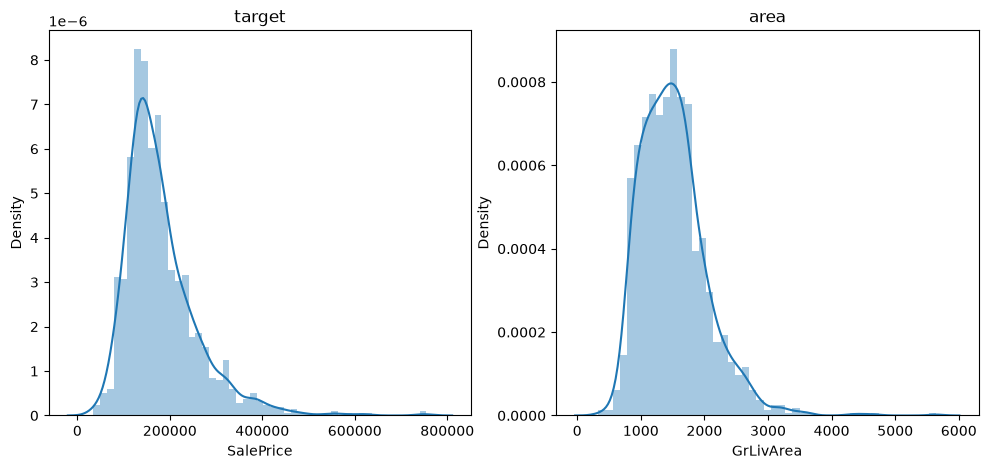

In [25]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.distplot(y, label='target')
plt.title('target')

plt.subplot(1, 2, 2)
sns.distplot(train_data.GrLivArea, label='area')
plt.title('area')
plt.show()

***Методом пристального взгляда*** можно заметить, что распределения площади и таргета сильно смещены и не являются нормальными

Давайте прологарифмируем таргет и посмотрим, что получится

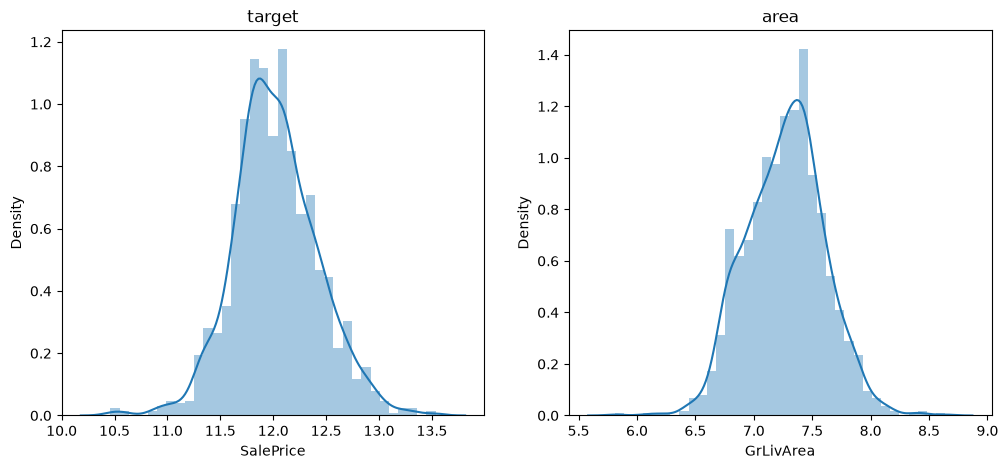

In [26]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.distplot(np.log(y+1), label='target')
plt.title('target')

plt.subplot(1, 2, 2)
sns.distplot(np.log(train_data.GrLivArea+1), label='area')
plt.title('area')
plt.show()

После логарифмирования мы получаем ***офигенное нормальное распределение*** для таргета и площади

Давайте теперь обучать модель не на истинное значение таргета, а на логарифм, а также признак GrLivArea прологарифмируем. 

***ВАЖНО***: когда будем считать качество модели, то нужно проэкспоненцировать результаты, чтобы получить значение цены квартиры

In [27]:
X_wo_cat = X[numeric_feats]
X_wo_cat['GrLivArea'] = X_wo_cat['GrLivArea'].apply(np.log1p)

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X_wo_cat, y, test_size = 0.3, random_state=10)

In [29]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [30]:
upgraded_model = LinearRegression()
upgraded_model.fit(X_train, np.log1p(y_train))
y_pred_log = upgraded_model.predict(X_test)
y_pred = np.exp(y_pred_log) - 1

In [31]:
rmse(y_test, y_pred)

np.float64(25911.602596354285)

Качество улучшилось на целых 6 тысяч, при этом мы вообще не использовали ***категориальные признаки*** и ***регуляризацию***

Давайте вспомним прошлое занятие, на котором разбиралась регуляризация.

Какие виды регуляризации вы знаете и чем они отличаются? ***(1 балл)***

Напишите формулу для L1 и L2 нормы. Какой вид функции потерь будет иметь модель, если к ней применить регуляризацию? ***(1 балл)***

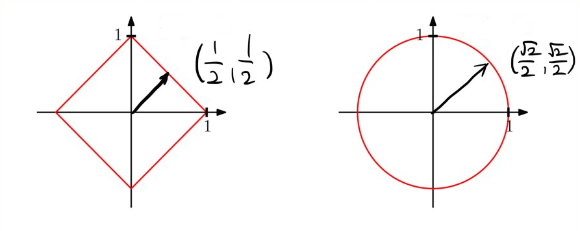

In [32]:
from IPython.display import Image
Image('img.png') 

In [32]:
ridge = Ridge()
ridge.fit(X_train, np.log1p(y_train))
y_pred_log = ridge.predict(X_test)
y_pred = np.exp(y_pred_log) - 1

In [33]:
rmse(y_test, y_pred)

np.float64(25914.217495731667)

Ridge (без подбора ***гиперпараметра***) дал прирост в 4 тысячи относительно самой первой модели 

Теперь давайте поговорим про то, как нужно работать с категориальными переменными. Давайте схитрим и будем менять значение конкретной категории на ***среднее значение таргета внутри категории***. Что это нам даст? Мы перейдём от категориальных переменных к числовым, нам не придётся увеличивать размерность признакового описания модели, и мы сможем использовать категориальные фичи для построения модели. 

***Какие подводные?*** Допустим, что в нашем датасете есть категория, которая встречается 1 раз во всём датасете. Её мы закодируем её же значением ***таргета***. Теперь у модели есть признак, по которому она на трейне всегда идеально может для этого объекта предсказать его таргет. Это ***переобучение***, потому что если эта редкая категория встретится в тесте, то мы не сможем честно посчитать для неё прогноз. Как быть?

Что такое ***кросс-валидация на k-foldах***? В каких случаях она может быть полезна? ***(1 балл)*** 

Давайте теперь будем использовать кросс-валидацию. А какие подвоные могут быть, если мы будем её использовать? (***Если кто-то догадается, то это сразу +3 балла и личная рекомендация Илье от меня***)

***Leave-one-out CV*** (LOO-CV) - это кросс-валидация на n-1 фолдах, где n - это размер выборки. Какой буст это нам даст? В обычной кросс-валидации у нас могли быть фолды, в которых слишком мало объектов опеределённой категории, поэтому мы опять могли переобучиться. Теперь же мы значение на i-ом объекте для какой-то категории используем среднее по таргету ***ВСЕХ*** объектов этой категории, кроме i-го.

In [45]:
!pip3 install category_encoders


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip


In [46]:
from category_encoders import LeaveOneOutEncoder

In [47]:
encoder = LeaveOneOutEncoder()

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=10)

In [49]:
X_train = encoder.fit_transform(X_train, y_train)
X_test = encoder.transform(X_test, y_test)

In [50]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [51]:
ridge = Ridge()
ridge.fit(X_train, np.log1p(y_train))
y_pred_log = ridge.predict(X_test)
y_pred = np.exp(y_pred_log) - 1

In [52]:
rmse(y_test, y_pred)

np.float64(23962.55162920881)

Сильного выигрыша это не дало, но значение функции потерь стало чуть меньше. Теперь попробуем подобрать единственный ***гиперпараметр*** - коэффициент регуляризации

In [34]:
from sklearn.model_selection import GridSearchCV

In [36]:
model = Ridge()
alphas = np.linspace(0.1, 5, 1000)
param_grid = {'alpha': alphas}

In [37]:
grid_search = GridSearchCV(estimator=model, 
                           param_grid=param_grid, 
                           cv=5, 
                           scoring='neg_root_mean_squared_error', 
                           n_jobs=-1)
grid_search.fit(X_train, np.log1p(y_train))

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': array([0.1 ..., 5. ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candidate 

In [38]:
params = grid_search.best_params_
params

{'alpha': np.float64(5.0)}

In [39]:
best_score = grid_search.best_score_
best_score

np.float64(-0.1638513681757539)

In [40]:
ridge = Ridge(**params)

In [41]:
ridge.fit(X_train, np.log1p(y_train))

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",np.float64(5.0)
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradi

In [42]:
y_pred = ridge.predict(X_test)

In [43]:
rmse(y_test, np.exp(y_pred)-1)

np.float64(25929.5259524406)